# Cellpose on brightfield, via scikit-ops

Brightfield cells, no custom model. Run the two built-ins -- CPSAM (Cellpose 4)
and cyto3 (Cellpose 3) -- at diameter 10, 30, 50, 100 and look at the masks.

Nothing Cellpose-related is installed in this kernel. `skop` runs each op in
an environment it builds and caches itself, which is how both Cellpose
versions work from one notebook.

## Install

```
conda create -n skop python=3.11
conda activate skop

pip install ipykernel matplotlib tifffile scikit-image tnia-python[plotting] \
    "scikit-ops @ git+https://github.com/apposed/scikit-ops.git"
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import tifffile

import skop
from skop.ops.segment import cellpose, cellpose3
from skop.ops.segment.cellpose3 import PretrainedModel
from tnia.plotting.plt_helper import mask_outline_overlay

plt.rcParams["figure.dpi"] = 72

IMAGE = Path(
    "/home/bnorthan/images/tnia-python-images/imagesc/2026_09_01_brightfield/brightfield.tif"
)
DIAMETERS = [10, 30, 50, 100]

## The image

(427, 480, 3) uint8, range 40-255


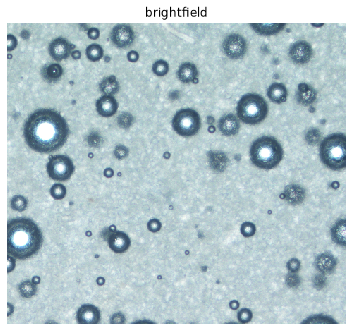

In [2]:
image = tifffile.imread(IMAGE)
print(f"{image.shape} {image.dtype}, range {image.min()}-{image.max()}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(image)
ax.set_title("brightfield")
ax.axis("off")
fig.tight_layout()

## The runner

A `Runner` is the session. It builds the environment an op declares, the first
time that op is called:

| op | Cellpose | environment |
| --- | --- | --- |
| `cellpose` | 4 (CPSAM) | `pytorch` |
| `cellpose3` | 3 (cyto3, nuclei, ...) | `cellpose3` |

Two environments, because Cellpose 3 and 4 cannot coexist in one. They land in
`~/.local/share/appose/skop-<environment>` and are shared by everything on this
machine -- notebooks, napari, anything.

First build is minutes and gigabytes (PyTorch, CUDA). After that it is cached.
`subscribe_build_progress` prints what a build is doing, so a first run does not
look like a hung kernel.

In [3]:
runner = skop.Runner()

_last = None


def on_build(title, current, maximum):
    global _last
    if title != _last:
        _last = title
        print("  [build]", title)


runner.subscribe_build_progress(on_build)

## Helper

In [10]:
def show_sweep(results, title):
    fig, axes = plt.subplots(2, 2, figsize=(10, 9))
    for ax, (d, labels) in zip(axes.flatten(), results.items()):
        ax.imshow(mask_outline_overlay(image, labels, color=(255, 0, 0), thickness=2))
        ax.set_title(f"diameter={d} -- {labels.max()} objects", fontsize=10)
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()

## CPSAM (Cellpose 4)

`cellpose` with no `model` argument is CPSAM -- it is the only model Cellpose 4
ships. The op greys the RGB image before handing it over; CPSAM has no channel
settings.

CPSAM estimates its own diameter when `diameter=0`, so the sweep below is mostly
a check of how much it cares. It usually does not care much.

In [11]:
cpsam = {}
for d in DIAMETERS:
    cpsam[d] = runner.run(cellpose, image=image, diameter=float(d))
    print(f"cpsam diameter={d:3d}  {cpsam[d].max()} objects")

cpsam diameter= 10  34 objects
cpsam diameter= 30  43 objects
cpsam diameter= 50  40 objects
cpsam diameter=100  52 objects


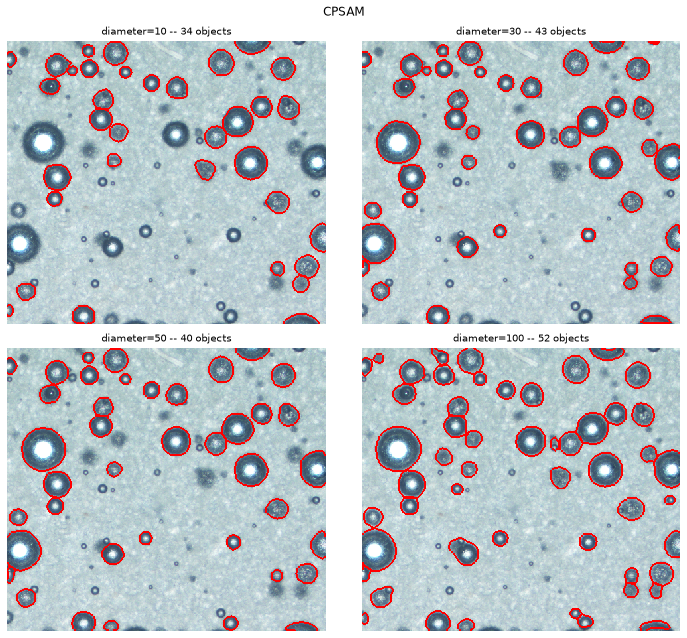

In [12]:
show_sweep(cpsam, "CPSAM")

## cyto3 (Cellpose 3)

Same sweep, other op. `model=PretrainedModel.cyto3` picks the built-in; type
`PretrainedModel.` and tab for the rest. Diameter is the setting that actually
drives Cellpose 3 -- it rescales the image so objects match the size the model
was trained on.

In [13]:
cyto3 = {}
for d in DIAMETERS:
    cyto3[d] = runner.run(
        cellpose3, image=image, model=PretrainedModel.cyto3, diameter=float(d)
    )
    print(f"cyto3 diameter={d:3d}  {cyto3[d].max()} objects")

cyto3 diameter= 10  36 objects
cyto3 diameter= 30  48 objects
cyto3 diameter= 50  26 objects
cyto3 diameter=100  14 objects


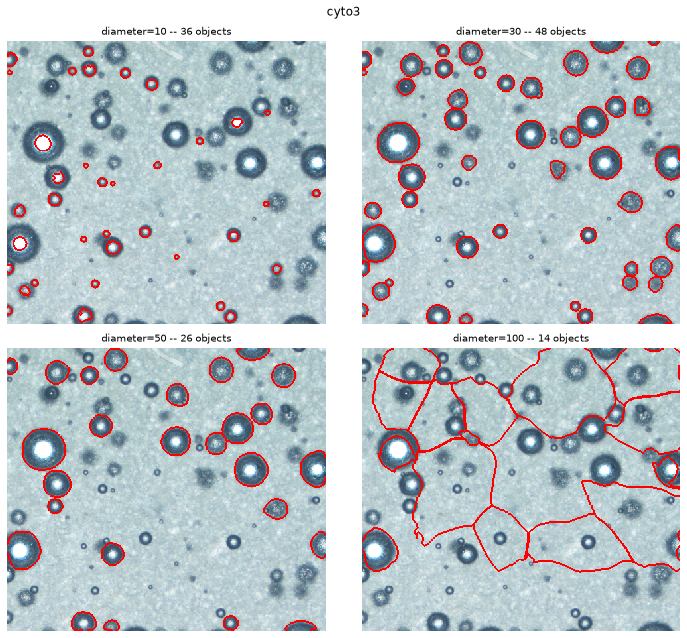

In [14]:
show_sweep(cyto3, "cyto3")

## Next, if nothing here works

Brightfield is out of distribution for both built-ins. Before training
anything, the knobs worth a second pass:

- `cellprob_threshold` -- lower keeps less confident pixels, so masks grow and
  more objects survive.
- `flow_threshold` -- raise it to stop good-but-odd-shaped masks being
  discarded.
- `min_size` -- the default 15 px quietly deletes small detections; `-1` keeps
  everything.
- inverting the image, so cells read bright on dark like the training data.

## Close the runner

Each environment that ran holds a worker process. Not optional -- a kernel
restarted without this leaves them running.

In [15]:
runner.close()